<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

<a href="https://query.farm/vgi/"><img src="assets/vgi-logo.png" alt="VGI" width="280"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Setup and provenance](README.md)

# 01 · Evaluate predictions before explaining them

**Does a boosted model predict held-out delivery times, and what adds up to one of
its predictions?** We will generate a small synthetic route table in SQL, withhold
one fifth of the rows, fit XGBoost through VGI, and calculate errors on both splits.
Then we will reconstruct predictions from the worker's SHAP contributions.

These are authored numbers, not observed deliveries. The target has a declared
nonlinear relationship plus a deterministic oscillating residual. The fixed split
illustrates the API and an evaluation discipline; it is not a temporal validation,
a deployment estimate, a causal study or a tuning benchmark.

## Set model complexity

`MAX_DEPTH` is the maximum tree depth, from 1 through 8. Keep the 80 boosting rounds,
learning rate and input rows fixed. Start with depth 2; the final experiment tries 6.
Restart the kernel and run all after changing it. Deeper trees may fit training rows
more closely without improving held-out error.

In [1]:
MAX_DEPTH = 2

In [2]:
import os
from tempfile import TemporaryDirectory

os.environ["PLOOMBER_STATS_ENABLED"] = "false"
import haybarn
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
from notebook_support import theme, finish, prose

if type(MAX_DEPTH) is not int or not 1 <= MAX_DEPTH <= 8:
    raise ValueError("MAX_DEPTH must be an integer from 1 through 8.")
model_directory = TemporaryDirectory(prefix="vgi-xgboost-example-")
previous_env = {
    k: os.environ.get(k) for k in ("XGBOOST_MODELS_DIR", "OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS")
}
os.environ["XGBOOST_MODELS_DIR"] = model_directory.name
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["OPENBLAS_NUM_THREADS"] = "1"
metrics = points = contributions = checks = pd.DataFrame()
theme()
con = haybarn.connect()
%load_ext sql
%config SqlMagic.autopandas = True
%config SqlMagic.feedback = False
%config SqlMagic.displaycon = False
%sql con
%matplotlib inline

Tip: You may define configurations in /Users/rusty/Development/notebook-rollout/full-rollout/checkouts/vgi-xgboost/notebooks/pyproject.toml or /Users/rusty/.jupysql/config.

Did not find user configurations in /Users/rusty/Development/notebook-rollout/full-rollout/checkouts/vgi-xgboost/notebooks/pyproject.toml.

## Attach the pinned worker

The visible command downloads an immutable public Git revision and runs its
unchanged entry point with pinned published dependencies. It needs Git and uv, not
a build of this checkout. The small launcher exists because this revision's wheel
does not package its worker entry point. Its implementation and pins are in
`worker_launcher.py`.

The named model will live in a fresh temporary directory, shared by this run's
worker processes. No existing registry is read or changed. Cleanup removes only
that directory. All connections here are local.

In [3]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'xgboost' (TYPE vgi, LOCATION 'uv run --no-project --python 3.13 python worker_launcher.py');
SELECT model_name,task FROM xgboost.main.list_models();

,model_name,task


## Build a reproducible population and declare the split

Distance, number of stops and a numeric rush-hour flag are the only features.
`route_id` is an identifier; `split` and `minutes` must never leak into predictors.
The target formula is visible below. Every fifth ID is held out, giving an explicit,
reproducible split before any fitting.

The sinusoid is an authored residual, not random measurement noise. Rows are
synthetic grid-like combinations, so this experiment does not justify assumptions
about exchangeability or real-world uncertainty.

In [4]:
%%sql
CREATE TABLE routes AS
WITH inputs AS (
 SELECT i AS route_id,2.0+(i*17%97)/3.0 AS distance_km,
        (1+i*7%9)::INTEGER AS stops,(i%3=0)::INTEGER AS rush
 FROM range(1,241) AS r(i)
)
SELECT *,CASE WHEN route_id%5=0 THEN 'Held out' ELSE 'Training' END AS split,
       12+0.8*distance_km+0.04*distance_km*distance_km
         +2.5*stops+8*rush+5*sin(route_id*1.73) AS minutes
FROM inputs;
SELECT split,count(*) AS routes,round(min(distance_km),2) AS min_km,
 round(max(distance_km),2) AS max_km,round(avg(minutes),2) AS mean_minutes
FROM routes GROUP BY split ORDER BY split;

,split,routes,min_km,max_km,mean_minutes
0,Held out,48,2.33,32.0,56.56
1,Training,192,2.00,34.0,58.34


## Fit once, excluding every audit column

`fit_xgb_regressor` buffers the training relation and exposes hyperparameters as
typed SQL arguments. Naming `route_id` as the ID and `minutes` as the target leaves
exactly three features. The returned model BLOB is retained in the local SQL table;
we display only its summary. `model_name` also saves the native model in our isolated
registry so later SQL cells can use it without a cursor-local variable.

Materializing the fit avoids a second training call when JupySQL captures or
displays a result. The held-out rows are absent from this call.

In [5]:
%%sql
CREATE TABLE fitted AS SELECT * FROM xgboost.main.fit_xgb_regressor(
 (SELECT route_id,distance_km,stops,rush,minutes FROM routes
  WHERE split='Training' ORDER BY route_id),
 model_name:='route_minutes',target:='minutes',id:='route_id',
 n_estimators:=80,max_depth:={{ MAX_DEPTH }},learning_rate:=0.1,random_state:=0);
SELECT model_name,estimator,task,n_samples,n_features FROM fitted;

,model_name,estimator,task,n_samples,n_features
0,route_minutes,xgb_regressor,regression,192,3


## Score both splits and calculate errors in SQL

Predictors contain neither the target nor the split. Join the returned ID back to
the audit table only after prediction. Root mean squared error (RMSE) and mean
absolute error (MAE) are in minutes. The baseline always predicts the training
mean, including for held-out rows; it never learns that split's target average.

In [6]:
%%sql
CREATE TABLE predictions AS SELECT * FROM xgboost.main.predict(
 (SELECT route_id,distance_km,stops,rush FROM routes ORDER BY route_id),
 model_name:='route_minutes',id:='route_id');
CREATE TABLE scored AS
 SELECT r.*,p.prediction,p.prediction-r.minutes AS error_minutes,
        (SELECT avg(minutes) FROM routes WHERE split='Training') AS baseline_minutes
 FROM routes r JOIN predictions p USING(route_id);
CREATE TABLE evaluation AS SELECT split,count(*) AS routes,
 sqrt(avg(error_minutes*error_minutes)) AS rmse_minutes,
 avg(abs(error_minutes)) AS mae_minutes,
 sqrt(avg(pow(baseline_minutes-minutes,2))) AS baseline_rmse_minutes
 FROM scored GROUP BY split;
SELECT split,routes,round(rmse_minutes,3) AS rmse_minutes,
 round(mae_minutes,3) AS mae_minutes,
 round(baseline_rmse_minutes,3) AS baseline_rmse_minutes
FROM evaluation ORDER BY split;

,split,routes,rmse_minutes,mae_minutes,baseline_rmse_minutes
0,Held out,48,5.530,4.642,20.645
1,Training,192,3.039,2.673,22.758


In [7]:
%%sql metrics <<
SELECT * FROM evaluation ORDER BY split;

In [8]:
%%sql points <<
SELECT * FROM scored ORDER BY route_id;

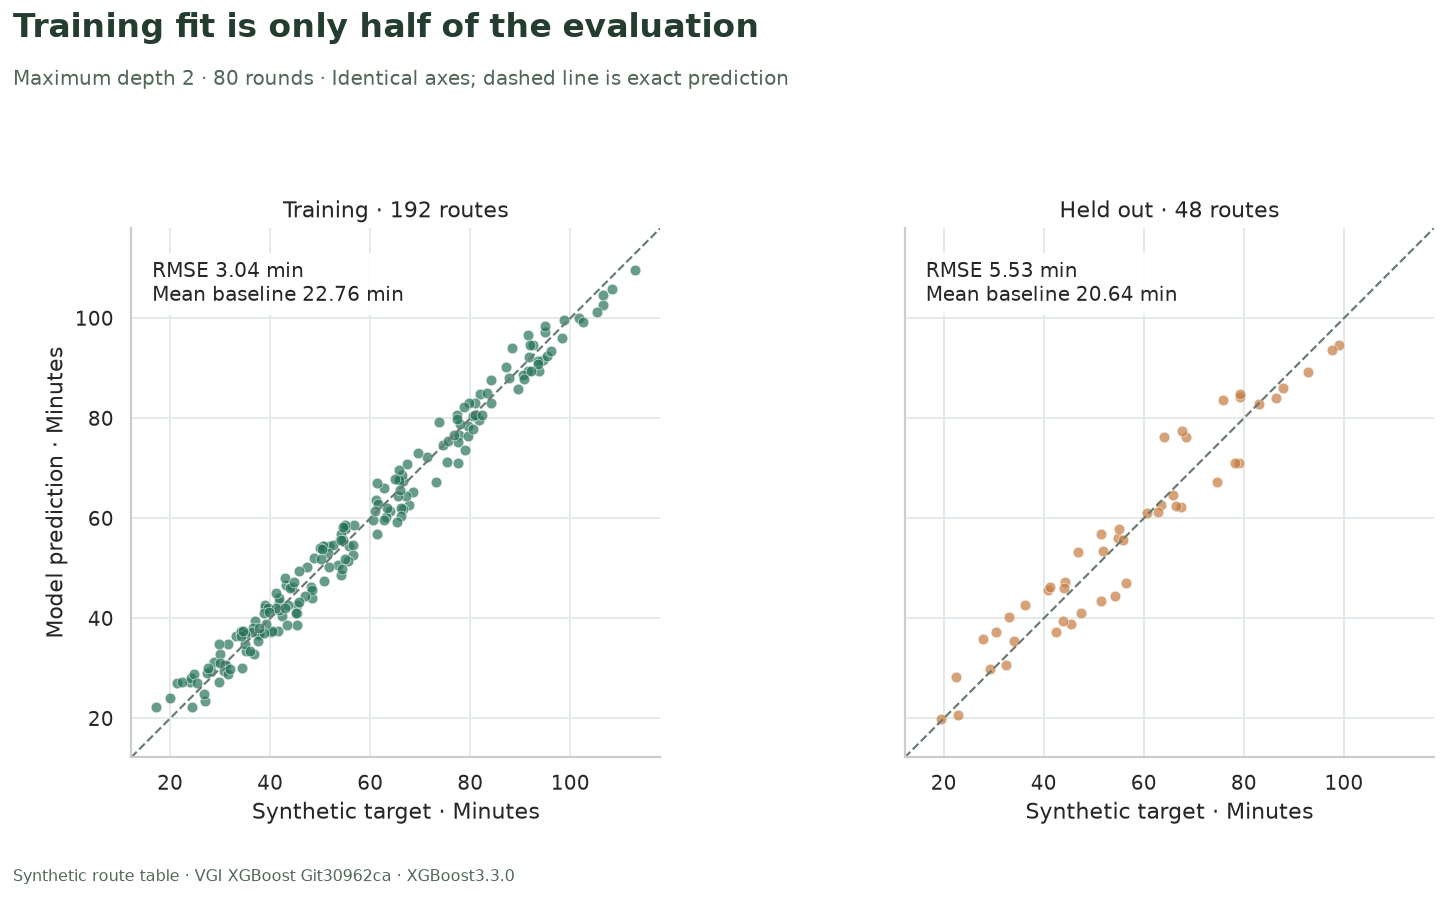

**Training RMSE is 3.04 minutes; held-out RMSE is 5.53 minutes.** The held-out mean baseline is 20.64 minutes. The two fitted-model errors answer different questions. Their gap is descriptive for this fixed synthetic split, not a confidence interval.

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 7), sharex=True, sharey=True)
lo = min(points.minutes.min(), points.prediction.min()) - 5
hi = max(points.minutes.max(), points.prediction.max()) + 5
for ax, split, color in zip(axes, ["Training", "Held out"], ["#267358", "#c57b40"], strict=True):
    group = points[points.split == split]
    stat = metrics[metrics.split == split].iloc[0]
    ax.scatter(
        group.minutes,
        group.prediction,
        s=35,
        alpha=0.7,
        color=color,
        edgecolors="white",
        linewidths=0.4,
    )
    ax.plot([lo, hi], [lo, hi], linestyle="--", color="#687b70", linewidth=1.2)
    ax.set(
        xlim=(lo, hi),
        ylim=(lo, hi),
        xlabel="Synthetic target · Minutes",
        title=f"{split} · {len(group)} routes",
    )
    ax.text(
        0.04,
        0.94,
        f"RMSE {stat.rmse_minutes:.2f} min\nMean baseline {stat.baseline_rmse_minutes:.2f} min",
        transform=ax.transAxes,
        va="top",
        fontsize=11,
        bbox={"facecolor": "white", "edgecolor": "none", "alpha": 0.9},
    )
    ax.set_aspect("equal", adjustable="box")
axes[0].set_ylabel("Model prediction · Minutes")
finish(
    fig,
    "Training fit is only half of the evaluation",
    f"Maximum depth {MAX_DEPTH} · 80 rounds · Identical axes; dashed line is exact prediction",
    "01_prediction_errors.png",
    bottom=0.12,
)
train = metrics[metrics.split == "Training"].iloc[0]
test = metrics[metrics.split == "Held out"].iloc[0]
prose(
    f"**Training RMSE is {train.rmse_minutes:.2f} minutes; held-out RMSE is {test.rmse_minutes:.2f} minutes.** "
    f"The held-out mean baseline is {test.baseline_rmse_minutes:.2f} minutes. "
    "The two fitted-model errors answer different questions. Their gap is descriptive for this fixed synthetic split, not a confidence interval."
)

## Explain the held-out predictions, then verify the arithmetic

`explain` returns one row per route and feature, with a repeated base value.
For this squared-error regressor, the raw margin is the prediction in minutes:
**one base value + the sum of feature contributions = the prediction**.
Use `max(base_value)` once per route; summing that repeated field would count it
three times. We check every held-out route before drawing one example.

A contribution attributes this fitted model's output. It does not establish a
feature's causal effect, prove correctness, or measure uncertainty. Classification
models generally explain margins rather than probabilities; this regression
identity should not be copied unchanged to a probability chart.

In [10]:
%%sql
CREATE TABLE explanations AS SELECT * FROM xgboost.main.explain(
 (SELECT route_id,distance_km,stops,rush FROM routes
  WHERE split='Held out' ORDER BY route_id),
 model_name:='route_minutes',id:='route_id');
CREATE TABLE reconstructed AS SELECT route_id,max(base_value) AS base_minutes,
 sum(shap_value) AS total_contribution_minutes,
 max(base_value)+sum(shap_value) AS reconstructed_minutes
 FROM explanations GROUP BY route_id;
SELECT count(*) AS held_out_routes,
 max(abs(reconstructed_minutes-p.prediction)) AS max_reconstruction_error_minutes
FROM reconstructed JOIN predictions p USING(route_id);
SELECT s.route_id,s.distance_km,s.stops,s.rush,s.minutes AS target_minutes,
 s.prediction,r.base_minutes,r.total_contribution_minutes
FROM scored s JOIN reconstructed r USING(route_id) WHERE route_id=200;

,route_id,distance_km,stops,rush,target_minutes,prediction,base_minutes,total_contribution_minutes
0,200,3.666667,6,0,32.531841,30.696407,58.341713,-27.645306


In [11]:
%%sql contributions <<
SELECT feature,shap_value,base_value FROM explanations
WHERE route_id=200 ORDER BY CASE feature WHEN 'distance_km' THEN 1 WHEN 'stops' THEN 2 ELSE 3 END;

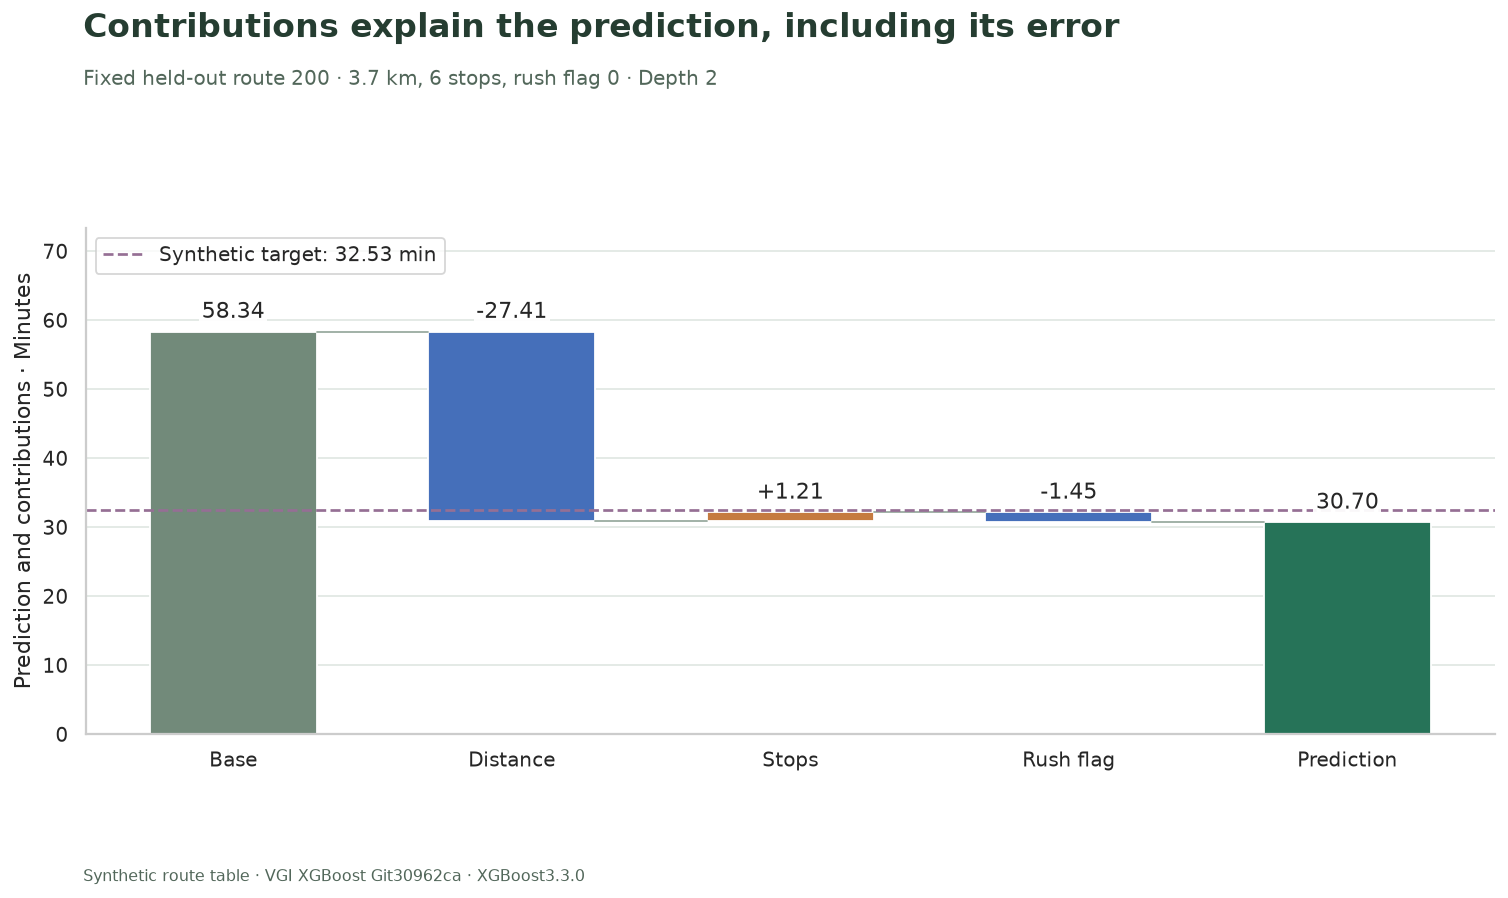

**Route 200: base 58.34 + contributions -27.65 = predicted 30.70 minutes.** The target is 32.53, leaving a signed error of -1.84 minutes. An additive explanation can be internally correct while the prediction still misses the target.

In [12]:
row = points[points.route_id == 200].iloc[0]
base = float(contributions.base_value.iloc[0])
current = base
fig, ax = plt.subplots(figsize=(12, 7))
labels = (
    ["Base"]
    + [
        {"distance_km": "Distance", "stops": "Stops", "rush": "Rush flag"}[f]
        for f in contributions.feature
    ]
    + ["Prediction"]
)
ax.bar(0, base, color="#728a7a", width=0.6)
ax.text(
    0,
    base + 2,
    f"{base:.2f}",
    ha="center",
    bbox={"facecolor": "white", "edgecolor": "none", "pad": 1.5, "alpha": 0.95},
)
for i, value in enumerate(contributions.shap_value, start=1):
    next_value = current + value
    ax.plot([i - 1 + 0.3, i - 0.3], [current, current], color="#9aaba0", linewidth=1)
    ax.bar(
        i,
        abs(value),
        bottom=min(current, next_value),
        color="#c57b40" if value >= 0 else "#456fba",
        width=0.6,
    )
    ax.text(
        i,
        max(current, next_value) + 2,
        f"{value:+.2f}",
        ha="center",
        bbox={"facecolor": "white", "edgecolor": "none", "pad": 1.5, "alpha": 0.95},
    )
    current = next_value
ax.plot([3.3, 3.7], [current, current], color="#9aaba0", linewidth=1)
ax.bar(4, row.prediction, color="#267358", width=0.6)
ax.text(
    4,
    row.prediction + 2,
    f"{row.prediction:.2f}",
    ha="center",
    bbox={"facecolor": "white", "edgecolor": "none", "pad": 1.5, "alpha": 0.95},
)
ax.axhline(
    row.minutes,
    color="#956f94",
    linestyle="--",
    linewidth=1.5,
    label=f"Synthetic target: {row.minutes:.2f} min",
)
ax.set_xticks(range(5), labels)
ax.set_ylabel("Prediction and contributions · Minutes")
ax.set_ylim(0, max(base, current, row.minutes) + 15)
ax.grid(axis="x", visible=False)
ax.legend(loc="upper left")
finish(
    fig,
    "Contributions explain the prediction, including its error",
    f"Fixed held-out route 200 · {row.distance_km:.1f} km, {int(row.stops)} stops, rush flag {int(row.rush)} · Depth {MAX_DEPTH}",
    "02_prediction_contributions.png",
    bottom=0.12,
)
prose(
    f"**Route 200: base {base:.2f} + contributions {contributions.shap_value.sum():+.2f} = predicted {row.prediction:.2f} minutes.** "
    f"The target is {row.minutes:.2f}, leaving a signed error of {row.error_minutes:+.2f} minutes. "
    "An additive explanation can be internally correct while the prediction still misses the target."
)

## Check the joins, population and explanation identity

These checks guard the mechanics: one prediction per input, training-only fitting,
three intended features, finite errors, and one contribution per feature on each
held-out row. They impose no desired ranking or error improvement when depth changes.

In [13]:
%%sql checks <<
SELECT 'Unique source IDs' AS check_name,count(*)=count(DISTINCT route_id) AS passed FROM routes
UNION ALL SELECT 'One prediction per input',count(*)=240 AND count(DISTINCT route_id)=240 FROM predictions
UNION ALL SELECT 'Join preserves all source rows',count(*)=240 FROM scored
UNION ALL SELECT 'Both split populations retained',count(*)=2 AND sum(routes)=240 FROM evaluation
UNION ALL SELECT 'Fit uses training only',n_samples=(SELECT count(*) FROM routes WHERE split='Training') FROM fitted
UNION ALL SELECT 'Exactly three intended features',n_features=3 AND task='regression' FROM fitted
UNION ALL SELECT 'Predictions and errors finite',bool_and(isfinite(prediction) AND isfinite(error_minutes)) FROM scored
UNION ALL SELECT 'Baseline uses training mean',bool_and(abs(baseline_minutes-(SELECT avg(minutes) FROM routes WHERE split='Training'))<1e-9) FROM scored
UNION ALL SELECT 'Explain covers held-out IDs exactly',count(*)=48 AND bool_and(s.split='Held out') FROM reconstructed r JOIN scored s USING(route_id)
UNION ALL SELECT 'One SHAP row per feature and route',count(*)=144 AND count(DISTINCT (route_id,feature))=144 FROM explanations
UNION ALL SELECT 'Repeated base is consistent',bool_and(span<1e-9) FROM (SELECT max(base_value)-min(base_value) AS span FROM explanations GROUP BY route_id)
UNION ALL SELECT 'SHAP reconstructs every held-out prediction',bool_and(abs(reconstructed_minutes-p.prediction)<0.0001) FROM reconstructed JOIN predictions p USING(route_id);

In [14]:
display(checks)
assert len(checks) == 12 and checks.passed.fillna(False).all(), checks
assert np.isclose(metrics.routes.sum(), len(points))
assert np.isclose(base + contributions.shap_value.sum(), row.prediction, atol=0.0001, rtol=0)
prose(
    f"**All {len(checks)} relationship checks passed.** No target error threshold is used as a correctness test."
)

,check_name,passed
0,Unique source IDs,True
1,One prediction per input,True
2,Join preserves all source rows,True
3,Both split populations retained,True
4,Fit uses training only,True
5,Exactly three intended features,True
6,Predictions and errors finite,True
7,Baseline uses training mean,True
8,Explain covers held-out IDs exactly,True
9,One SHAP row per feature and route,True


**All 12 relationship checks passed.** No target error threshold is used as a correctness test.

## Try one controlled change

Set **`MAX_DEPTH = 6`**, restart the kernel and run all. Predict whether training
RMSE will fall, then compare held-out RMSE with both its original value and the
training-mean baseline. Also compare the fixed route 200's contribution chart:
the input row and target stay fixed while the fitted explanation may change.

The synthetic table, split, boosting rounds and learning rate stay fixed. Two depth
settings do not identify an optimal model. After inspecting results, these held-out
rows have informed your choice; a final unbiased assessment would need untouched
validation data. Reset **`MAX_DEPTH = 2`** to reproduce the saved example.

In [15]:
con.close()
model_directory.cleanup()
for key, value in previous_env.items():
    if value is None:
        os.environ.pop(key, None)
    else:
        os.environ[key] = value

<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Notebook setup](README.md)